# TC5061 - Exploración de reservas de hoteles

| | |
|---|---|
| Alumno | Francisco Vicente Eugenio Ponce |
| Matrícula | A01840479 |
| Curso | TC5061 Operaciones de aprendizaje automático (MLOps) |
| Entregable | `TC5061_Notebook_Baseline_EugenioFrancisco.ipynb` |

## 1. Datos y objetivo

Uso el dataset *Hotel booking demand*, descargado de Kaggle, con reservas de dos hoteles en Portugal entre 2015 y 2017. El objetivo es predecir si una reserva se cancela (`is_canceled = 1`).

En este notebook exploro los datos y reviso la limpieza. La regresión logística se entrena y evalúa en `train.py`. El CSV debe estar en `data/hotel_bookings.csv`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 32)
data = pd.read_csv("data/hotel_bookings.csv")
print(f"Registros: {len(data):,} | Variables: {data.shape[1]}")
data.info()
display(data.head())


Registros: 119,390 | Variables: 32
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Significado de las variables

El archivo tiene **119,390 registros y 32 variables**: 16 enteras, 4 de punto flotante y 12 de texto. Cada registro es una reserva. La tabla resume el significado de las variables del dataset descargado de Kaggle.

| Variable | Tipo en el archivo | Tipo conceptual | Significado |
|---|---|---|---|
| `is_canceled` | int | Binaria (**objetivo**) | 1 si la reserva se canceló, 0 si no |
| `hotel` | texto | Categórica | *City Hotel* (Lisboa) o *Resort Hotel* (Algarve) |
| `lead_time` | int | Numérica | Días entre el registro de la reserva y la fecha de llegada |
| `arrival_date_year` | int | Temporal | Año de llegada (2015 a 2017) |
| `arrival_date_month` | texto | Temporal | Mes de llegada, en inglés |
| `arrival_date_week_number` | int | Temporal | Semana del año de la llegada |
| `arrival_date_day_of_month` | int | Temporal | Día del mes de la llegada |
| `stays_in_weekend_nights` | int | Numérica | Noches de sábado o domingo reservadas |
| `stays_in_week_nights` | int | Numérica | Noches de lunes a viernes reservadas |
| `adults` | int | Numérica | Número de adultos |
| `children` | float | Numérica | Número de niños |
| `babies` | int | Numérica | Número de bebés |
| `meal` | texto | Categórica | Plan de alimentos: BB (desayuno), HB (media pensión), FB (pensión completa), SC o Undefined (sin plan) |
| `country` | texto | Categórica | País de origen en código ISO de tres letras |
| `market_segment` | texto | Categórica | Segmento de mercado (TA es agencia de viajes, TO es operador turístico) |
| `distribution_channel` | texto | Categórica | Canal de distribución de la reserva |
| `is_repeated_guest` | int | Binaria | 1 si el huésped ya se había hospedado antes |
| `previous_cancellations` | int | Numérica | Reservas previas canceladas por el mismo cliente |
| `previous_bookings_not_canceled` | int | Numérica | Reservas previas no canceladas por el mismo cliente |
| `reserved_room_type` | texto | Categórica | Código del tipo de habitación reservada |
| `assigned_room_type` | texto | Categórica | Código del tipo de habitación asignada, que puede diferir de la reservada |
| `booking_changes` | int | Numérica | Cambios hechos a la reserva hasta el check-in o la cancelación |
| `deposit_type` | texto | Categórica | *No Deposit*, *Non Refund* (pago total no reembolsable) o *Refundable* |
| `agent` | float | Identificador | ID de la agencia que hizo la reserva; nulo si no hubo agencia |
| `company` | float | Identificador | ID de la empresa que hizo o paga la reserva; nulo si no hubo empresa |
| `days_in_waiting_list` | int | Numérica | Días en lista de espera antes de confirmarse |
| `customer_type` | texto | Categórica | *Transient*, *Transient-Party*, *Contract* o *Group* |
| `adr` | float | Numérica | Tarifa diaria promedio (*Average Daily Rate*), en euros |
| `required_car_parking_spaces` | int | Numérica | Cajones de estacionamiento solicitados |
| `total_of_special_requests` | int | Numérica | Número de peticiones especiales (cama extra, piso alto, etc.) |
| `reservation_status` | texto | Categórica | Último estado: *Check-Out*, *Canceled* o *No-Show* |
| `reservation_status_date` | texto | Fecha | Fecha en que se fijó el último estado |

## 2. Exploración

Reviso el objetivo, las distribuciones y las diferencias entre categorías. La exploración usa todo el archivo; esto puede influir en las decisiones previas a la partición. En un proyecto posterior reservaría prueba antes del EDA.

In [2]:
# Estadísticas y problemas de calidad antes de limpiar.
numericas = ["lead_time", "adr", "adults", "children", "babies",
             "stays_in_week_nights", "stays_in_weekend_nights"]
display(data[numericas].describe().T)
display(data[["hotel", "meal", "market_segment", "deposit_type"]].describe().T)
display(data.isna().sum().loc[lambda x: x > 0].rename("faltantes"))
print("Filas repetidas:", data.duplicated().sum())
print("Cancelación (%):", round(data["is_canceled"].mean() * 100, 2))

# Indicio de posible fuga; no demuestra cuándo se capturó la variable.
estacionamiento = data.loc[data["required_car_parking_spaces"] > 0, "is_canceled"]
print(f"Con estacionamiento: {len(estacionamiento):,} reservas; "
      f"{int(estacionamiento.sum()):,} canceladas")


,count,mean,std,min,25%,50%,75%,max
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
adr,119390.0,101.831122,50.535790,-6.38,69.29,94.575,126.0,5400.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
meal,119390,5,BB,92310
market_segment,119390,8,Online TA,56477
deposit_type,119390,3,No Deposit,104641


children         4
country        488
agent        16340
company     112593
Name: faltantes, dtype: int64

Filas repetidas: 31994
Cancelación (%): 37.04
Con estacionamiento: 7,416 reservas; 0 canceladas


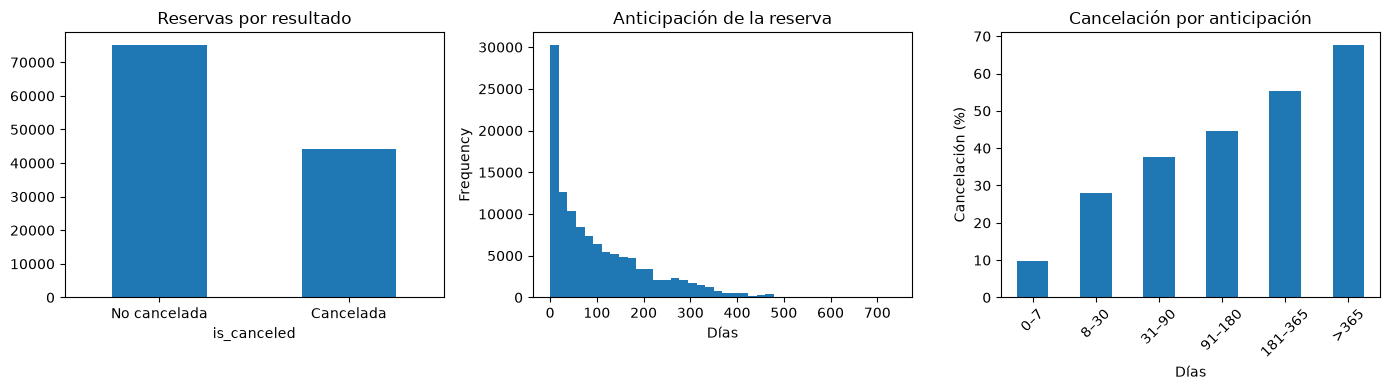

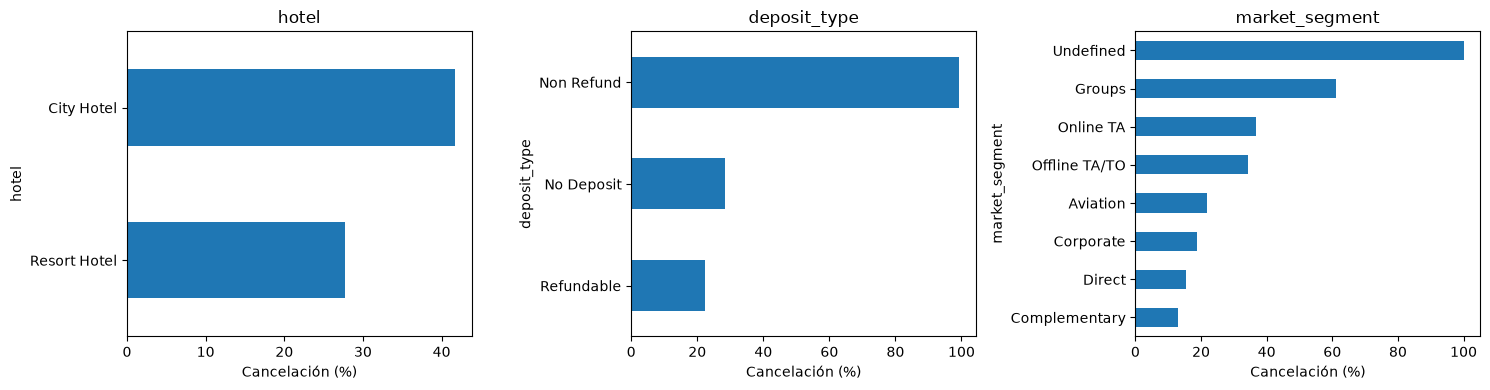

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
data["is_canceled"].value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Reservas por resultado")
axes[0].set_xticklabels(["No cancelada", "Cancelada"])
data["lead_time"].plot.hist(bins=40, ax=axes[1])
axes[1].set_title("Anticipación de la reserva")
axes[1].set_xlabel("Días")
# Cancelación por anticipación, además de su distribución.
rangos = pd.cut(data["lead_time"], bins=[-1, 7, 30, 90, 180, 365, float("inf")],
                labels=["0–7", "8–30", "31–90", "91–180", "181–365", ">365"])
tasa_lead = data.groupby(rangos, observed=True)["is_canceled"].mean() * 100
tasa_lead.plot.bar(ax=axes[2], rot=45)
axes[2].set_title("Cancelación por anticipación")
axes[2].set_xlabel("Días")
axes[2].set_ylabel("Cancelación (%)")
plt.tight_layout()
plt.show()

# Relación de categorías con la cancelación.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, columna in zip(axes, ["hotel", "deposit_type", "market_segment"]):
    tasas = data.groupby(columna)["is_canceled"].mean().sort_values() * 100
    tasas.plot.barh(ax=ax)
    ax.set_title(columna)
    ax.set_xlabel("Cancelación (%)")
plt.tight_layout()
plt.show()

Se cancela el 37.0 % de las reservas. City Hotel presenta más cancelaciones que Resort Hotel (41.7 % frente a 27.8 %). Destaca *Non Refund*, con 99.4 %; revisaré las filas repetidas antes de interpretar ese patrón.

La anticipación tiene una cola larga y la tarifa incluye un valor negativo y otro de 5,400 euros. También aparecen hasta 55 adultos por reserva. Son casos que requieren revisión, no errores demostrados solo por ser extremos.

La cancelación aumenta de 9.6 % con una semana o menos de anticipación a 67.7 % con más de un año. Esto respalda probar `lead_time` como predictor, sin atribuirle causalidad.


## 3. Limpieza

Estas son las decisiones para el baseline:

- Quito filas idénticas para evitar que una misma observación aparezca en entrenamiento y prueba. Sin un identificador, algunas podrían ser reservas legítimas de grupos; es el supuesto más importante de la limpieza.
- Completo los cuatro faltantes de `children` con 0 como aproximación sencilla. Uso `Unknown` en país para no asignar una nacionalidad sin evidencia. En `agent` y `company`, interpreto los nulos como ausencia de agencia o empresa para este baseline; uso banderas de presencia en lugar de inventar identificadores.
- Unifico `meal = Undefined` con `SC`, interpretando ambas categorías como ausencia de plan de alimentos para este análisis. Elimino las cinco filas con segmento o canal indefinido por su escaso número.
- Convierto niños e identificadores a enteros porque son conteos o códigos, y la fecha de estado a fecha para representarla correctamente.
- Excluyo reservas sin huéspedes y tarifas negativas por ser inconsistentes con el problema. También retiro tarifas mayores a 1,000 euros, más de 10 adultos, 10 o más niños o 9 o más bebés para limitar la influencia de casos extremos: son límites propuestos, no errores confirmados. Conservo tarifas y noches iguales a cero, que podrían ser legítimas.


In [4]:
df = data.drop_duplicates().copy()
print(f"Tras duplicados: {len(df):,} filas ({len(data) - len(df):,} eliminadas)")

# Faltantes y variables de presencia.
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")
df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)
df[["agent", "company"]] = df[["agent", "company"]].astype("Int64")
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])

# Categorías equivalentes y registros sin segmento o canal conocido.
df["meal"] = df["meal"].replace("Undefined", "SC")
definidas = (df["market_segment"] != "Undefined") & (df["distribution_channel"] != "Undefined")
print(f"Filas con segmento o canal indefinido: {(~definidas).sum():,}")
df = df.loc[definidas].copy()
print(f"Tras categorías indefinidas: {len(df):,} filas")

# Filtros acordes con los supuestos descritos arriba.
huespedes = df["adults"] + df["children"] + df["babies"]
conservar = (
    (huespedes > 0) & df["adr"].between(0, 1000)
    & (df["adults"] <= 10) & (df["children"] < 10) & (df["babies"] < 9)
)
print(f"Filas retiradas por filtros: {(~conservar).sum():,}")
df = df.loc[conservar].reset_index(drop=True)
print(f"Tras filtros: {len(df):,} filas")

display(pd.DataFrame({
    "original": [len(data), data["is_canceled"].mean(), data.duplicated().sum()],
    "limpio": [len(df), df["is_canceled"].mean(), df.duplicated().sum()],
}, index=["filas", "proporción cancelada", "duplicados"]))
print("Nulos en niños y país:", df[["children", "country"]].isna().sum().sum())

# Reviso el patrón de Non Refund después de la limpieza.
for nombre, tabla in [("Original", data), ("Limpio", df)]:
    grupo = tabla.loc[tabla["deposit_type"] == "Non Refund", "is_canceled"]
    print(f"Non Refund ({nombre}): {len(grupo):,} reservas; {grupo.mean():.1%} canceladas")


Tras duplicados: 87,396 filas (31,994 eliminadas)
Filas con segmento o canal indefinido: 5
Tras categorías indefinidas: 87,391 filas
Filas retiradas por filtros: 183
Tras filtros: 87,208 filas


,original,limpio
filas,119390.000000,87208.000000
proporción cancelada,0.370416,0.275101
duplicados,31994.000000,0.000000


Nulos en niños y país: 0
Non Refund (Original): 14,587 reservas; 99.4% canceladas
Non Refund (Limpio): 1,037 reservas; 94.7% canceladas


Quedan 87,208 reservas y la cancelación baja a 27.5 %. Casi toda la reducción viene de quitar 31,994 filas repetidas. Esto cambia la población evaluada: si esas filas fueran reservas legítimas, estaríamos subrepresentando sus cancelaciones.

En *Non Refund*, las reservas pasan de 14,587 a 1,037 y la cancelación sigue siendo alta (94.7 %). Quitar repetidos reduce el peso del grupo, pero no elimina el patrón.


## Experimentación
El entrenamiento, la evaluación y el registro en MLflow están en `train.py`. Este notebook conserva la exploración y la revisión de limpieza. Consulta `README.md` para ejecutar las corridas.

## Referencias

- *Hotel booking demand* [Conjunto de datos]. (2020). Kaggle. https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand
- Géron, A. (2019). *Hands-on Machine Learning with Scikit-Learn, Keras and TensorFlow* (2.ª ed.). O’Reilly. Capítulo 2.
- Treveil, M., et al. (2020). *Introducing MLOps*. O’Reilly. Capítulo 4.
- MLflow. *MLflow Tracking*. https://mlflow.org/docs/latest/ml/tracking/